In [2]:
#%matplotlib widget
import pandas as pd
import numpy as np
from plotting_params import use_my_style
import matplotlib.pyplot as plt
use_my_style()
from pathlib import Path
import astropy.constants as const
from scipy.ndimage import median_filter

# 1) Load telluric-corrected spectrum (for 1 observation)

also, normalise flux and uncertainty

In [ ]:
tel_corrected_file = "/home/alst3712/exocomet_project/clean_data/2022-04-05_M4368/order_regions/tellurics_corrected_parallelised_2022-04-05_M4368.dat"
observed = pd.read_csv(tel_corrected_file, comment="#", names=["wavelength", "flux", "error"], delimiter=r"\s+")

wavelength=observed["wavelength"].to_numpy()
observed_flux=observed["flux"].to_numpy()
observed_error=observed["error"].to_numpy()

wavelength = wavelength / 1000 # convert nm to microns


#sort just in case
order = np.argsort(wavelength)
wavelength = wavelength[order]
observed_flux = observed_flux[order]
observed_error = observed_error[order]

norm_constant = np.nanmedian(observed_flux)
observed_flux_norm = observed_flux / norm_constant
observed_error_norm = observed_error / np.abs(norm_constant)
print(f' Flux norm factor is {norm_constant:.3e}')

dx = np.diff(wavelength)
typical_spacing = np.nanmedian(dx[dx > 0])

gap_indices = np.where(dx > 2 * typical_spacing)[0]

wavelength_plot = np.insert(wavelength, gap_indices + 1, np.nan)
flux_plot = np.insert(observed_flux_norm, gap_indices + 1, np.nan)
error_plot = np.insert(observed_error_norm, gap_indices + 1, np.nan)

min_wavelength_obs, max_wavelength_obs  = np.min(wavelength), np.max(wavelength)

 Flux norm factor is 3.966e+04


In [31]:
median_SNR = np.nanmedian(observed_flux_norm/observed_error_norm)
print(f'The median SNR is {median_SNR:.2f}')
# def shifted_model(v):
#     return np.interp(wavelength / (1 + v / const.c.to('km/s').value), wavelength, observed_flux_norm)

The median SNR is 47.47


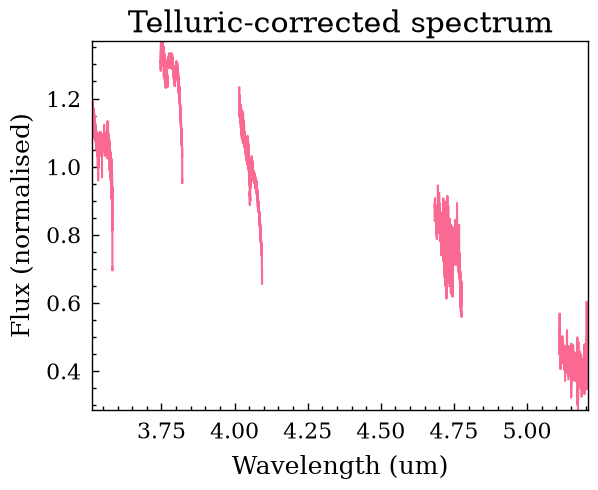

In [3]:
plt.close()
plt.plot(wavelength_plot, flux_plot)
plt.xlabel('Wavelength (um)')
plt.ylabel('Flux (normalised)')
plt.title('Telluric-corrected spectrum')
#plt.ylim(0, 2)
plt.show()

# Remove spikes (now done prior to telluric correction)

In [4]:
# ### REMOVE SPIKES
# WINDOW = 15
# SPIKE_SIGMA = 8

# if WINDOW % 2 == 0:
#     raise ValueError('WINDOW must be an odd number')

# local_median = median_filter(observed_flux, size=WINDOW)
# residual = observed_flux - local_median

# local_residual_median = median_filter(
#     residual,
#     size=WINDOW,
#     mode="nearest",
# )
# absolute_deviation = np.abs(
#     residual - local_residual_median
# )
# local_mad = median_filter(
#     absolute_deviation,
#     size=WINDOW,
#     mode="nearest",
# )
# local_sigma = 1.4826 * local_mad #for normally distributed noise

# noise_scale = np.maximum(local_sigma, observed_error)
# spike_mask = (
#     np.abs(residual) > SPIKE_SIGMA * noise_scale
# )

# print(f"Spikes identified: {np.sum(spike_mask)}")

# fig, ax = plt.subplots(figsize=(14, 5))

# ax.plot(
#     wavelength,
#     observed_flux,
#     color="black",
#     linewidth=0.7,
#     label="Original spectrum",
# )

# ax.scatter(
#     wavelength[spike_mask],
#     observed_flux[spike_mask],
#     color="red",
#     s=25,
#     label="Flagged spikes",
#     zorder=3,
# )

# ax.plot(
#     wavelength,
#     local_median,
#     color="tab:blue",
#     linewidth=1,
#     alpha=0.8,
#     label="Local median",
# )

# ax.set_xlabel("Wavelength [um]")
# ax.set_ylabel("Flux")
# ax.set_title("Detecting extreme local spikes")
# ax.legend()
# ax.grid(alpha=0.2)

# plt.tight_layout()
# plt.show()

# 2) Load one of the CO cross-section CSVs (for 1 temperature)

In [32]:
model_file_1000K = '/home/alst3712/exocomet_project/Opacity_spectra/data/processed/CO_T1000K.csv'
co_model_1000K = pd.read_csv(model_file_1000K)

cross_section = co_model_1000K['cross_section_cm2_molecule'].to_numpy()
model_wavelength = co_model_1000K['wavelength_um'].to_numpy()

# again, make sure they are ordered:

model_order = np.argsort(model_wavelength)
model_wavelength = model_wavelength[model_order]
cross_section = cross_section[model_order]

print(
        f"CO model wavelength range: "
        f"{model_wavelength.min():.5f}–"
        f"{model_wavelength.max():.5f} um"
        )

## only care about the wavelengths that the data has:

inside_M_band_extended = ((model_wavelength >= min_wavelength_obs-0.05) & 
        (model_wavelength <= max_wavelength_obs+0.05))

inside_M_band = ((model_wavelength >= min_wavelength_obs) & 
        (model_wavelength <= max_wavelength_obs))


model_wavelength_M_band = model_wavelength[inside_M_band_extended]
cross_section_M_band = cross_section[inside_M_band_extended]

synth_wavelength_M_band = model_wavelength[inside_M_band]

inside_J_band_extended = ((model_wavelength >= 1.1-0.01) & 
        (model_wavelength <= 1.4+0.01))

inside_J_band = ((model_wavelength >= 1.1) & 
        (model_wavelength <= 1.4))

model_wavelength_J_band = model_wavelength[inside_J_band_extended]
cross_section_J_band = cross_section[inside_J_band_extended]

synth_wavelength_J_band = model_wavelength[inside_J_band]


#print(f'Range we need for our data: {np.min(model_wavelength):.4f} - {np.max(model_wavelength):.4f} um')

CO model wavelength range: 0.50003–29.99850 um


# 3) Convert the cross-section into an absorption specrum

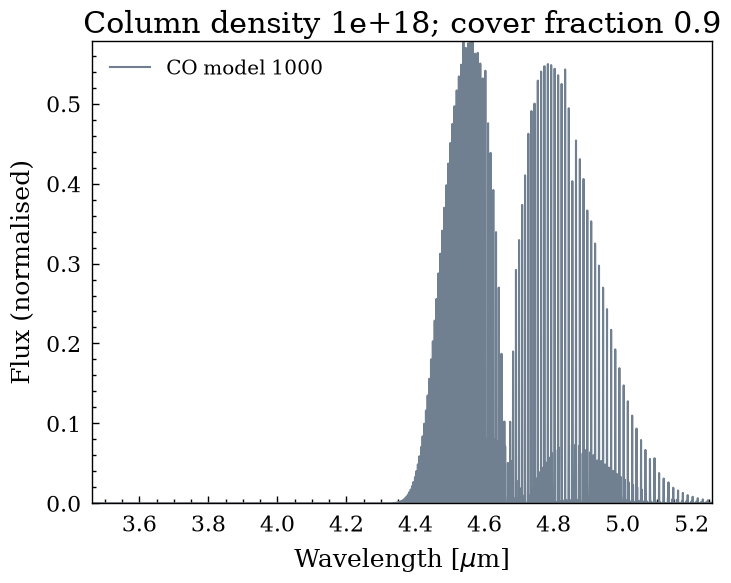

In [52]:
def make_co_template(column_density, c_f, cross_section_grid):
    # Optical depth:
    # tau = N_CO * sigma
    #
    # Units:
    # molecules/cm^2 * cm^2/molecule = dimensionless.

    optical_depth = column_density * cross_section_grid

    # Beer-Lambert law for pure absorption.

    # Partial covering:
    # a fraction f of the stellar continuum is covered by gas,
    # while the remaining fraction 1-f is unobscured.

    transmission = np.exp(-optical_depth)
    absorption = c_f * (1 - transmission)

    # Approximate instrumental broadening with a Gaussian line-spread
    # function. We convolve the transmission, not the optical depth.
    #
    # For resolving power R, the approximate Gaussian sigma in
    # log(wavelength) is 1 / (2.355 * R).

    # sigma_pixels = (
    #     1 / (2.355 * 10000)
    # ) / dlog_wavelength

    # transmission_broadened = gaussian_filter1d(
    #     transmission,
    #     sigma=sigma_pixels,
    #     mode="nearest",
    # )


    return absorption, transmission


# save for a range of column densities and cover fractions (and eventually temperatures by changing the model file)

column_density = 1e18
cd_J = 1e25
cover_fraction = 0.9


absorption_Mband, transmission_Mband = make_co_template(column_density, cover_fraction, cross_section_M_band)
absorption_Jband, transmission_Jband = make_co_template(cd_J, cover_fraction, cross_section_J_band)

model_output_M = pd.DataFrame({'wavelength': model_wavelength_M_band, 'flux_transmission': transmission_Mband})
model_output_M.to_csv(f'Opacity_spectra/CO_absorptions/CO_model_transmission_Mband_{column_density:.1e}_{cover_fraction}.dat')

model_output_J = pd.DataFrame({'wavelength': model_wavelength_J_band, 'flux_transmission': transmission_Jband})
model_output_J.to_csv(f'Opacity_spectra/CO_absorptions/CO_model_transmission_Jband_{cd_J:.1e}_{cover_fraction}.dat')
#plot

plt.close()
fig, ax= plt.subplots(figsize=(8,6))

plt.plot(model_wavelength_M_band, absorption_Mband, c='slategrey', label='CO model 1000 ')
ax.ticklabel_format(useOffset=False)
#plt.ylim(0.999999, 1)
plt.ylabel('Flux (normalised)')
plt.xlabel(r'Wavelength [$\mu$m]')
plt.title(f'Column density {column_density:.0e}; cover fraction {cover_fraction}')
plt.legend()
plt.show()

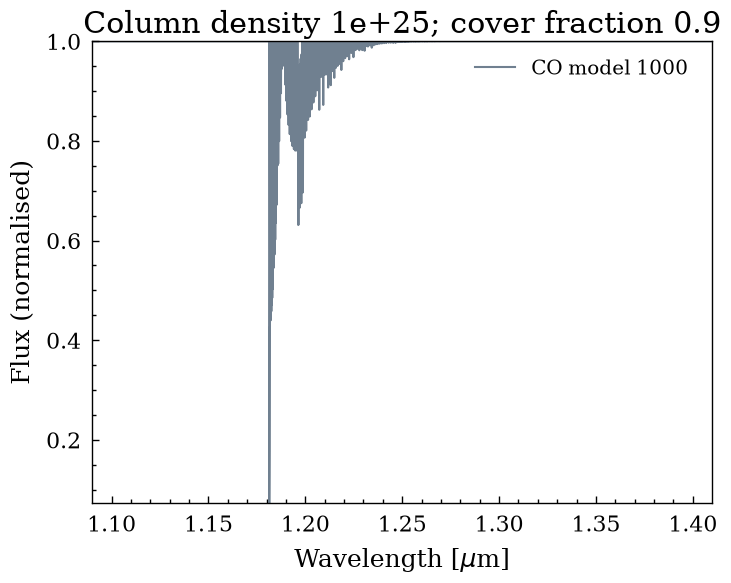

In [53]:
fig, ax= plt.subplots(figsize=(8,6))

plt.plot(model_wavelength_J_band, transmission_Jband, c='slategrey', label='CO model 1000 ')
#ax.ticklabel_format(useOffset=False)
#plt.ylim(0.999999, 1)
plt.ylabel('Flux (normalised)')
plt.xlabel(r'Wavelength [$\mu$m]')
plt.title(f'Column density {cd_J:.0e}; cover fraction {cover_fraction}')
plt.legend()
plt.show()

# Make a simple "fake" observation

In [9]:
# fake_velocity =  20 #in km/s; hide the CO signal here! hihi)
# signal_strength = 1

# absorption = shifted_model(fake_velocity) - 1
# noise = np.random.normal(0, 1 / median_SNR, len(wavelength))
# synthetic_spectrum = 1 + signal_strength * absorption + noise


# Get a synthetic spectrum from SVO 2

In [54]:
def get_synth_spectrum(model_wvl):

    data = pd.read_csv('lte080-4.5-0.5a+0.0.BT-NextGen.7.dat.txt', sep=r'\s+', comment ="#", header=None, names=['wavelength', 'flux'])

    res = np.interp(model_wvl, data['wavelength']/10000, #angstrom to micrometer
                    data['flux'])

    # Estimate the noise standard deviation
    sigma = np.abs(res) / median_SNR

    rng = np.random.default_rng(42)
    noisy_flux = res + rng.normal(0, sigma)

    # FIT THE CONTINUUM FIRST  
    coeff = np.polyfit(model_wvl, noisy_flux, deg=3)
    continuum = np.polyval(coeff, model_wvl)
    #fake_norm_const = np.median(noisy_flux)

    normed_flux = noisy_flux/continuum

    return normed_flux

synth_flux_Jband = get_synth_spectrum(synth_wavelength_J_band)
synth_flux_Mband = get_synth_spectrum(synth_wavelength_M_band)

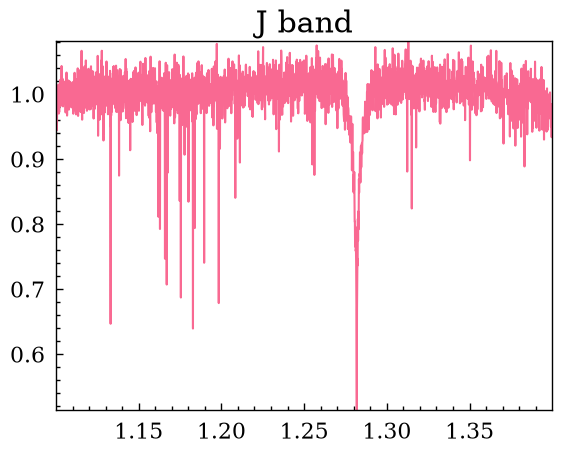

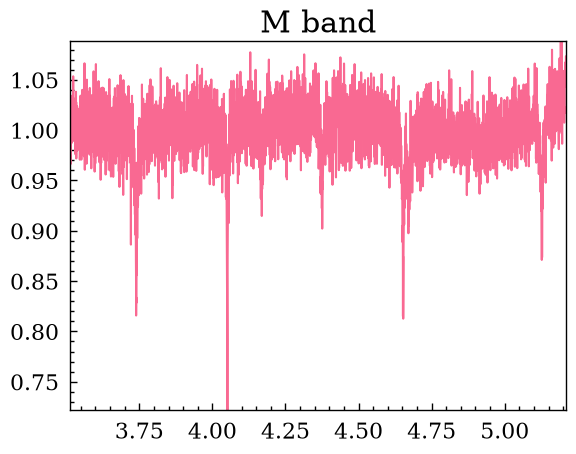

In [55]:
plt.plot(synth_wavelength_J_band, synth_flux_Jband)
plt.title('J band')
plt.show()
plt.plot(synth_wavelength_M_band, synth_flux_Mband)
plt.title('M band')
plt.show()

In [11]:
model_wavelength_J_band, synth_flux_Jband

(array([1.09001588, 1.09012489, 1.0902339 , ..., 1.40971673, 1.40985771,
        1.4099987 ], shape=(2575,)),
 array([1.43733315, 1.39687457, 1.45281799, ..., 0.64993802, 0.67412719,
        0.67213422], shape=(2411,)))

## deal with gaps

In [12]:
# dx = np.diff(wavelength)
# dx2 = np.diff(model_wavelength)

# gap_indices = np.where(dx > 2 * np.median(dx[dx>0]))[0]
# gap_indices2 = np.where(dx2 > 2 * np.median(dx2[dx2>0]))[0]

# new_wavelength = np.insert(wavelength, gap_indices + 1, np.nan)
# new_obs_flux_norm = np.insert(observed_flux_norm, gap_indices + 1, np.nan)
# new_synth_flux_norm = np.insert(synth_flux_Jband, gap_indices + 1, np.nan)

# Plot everything together: synthetic spectrum, observed spectrum, and CO template

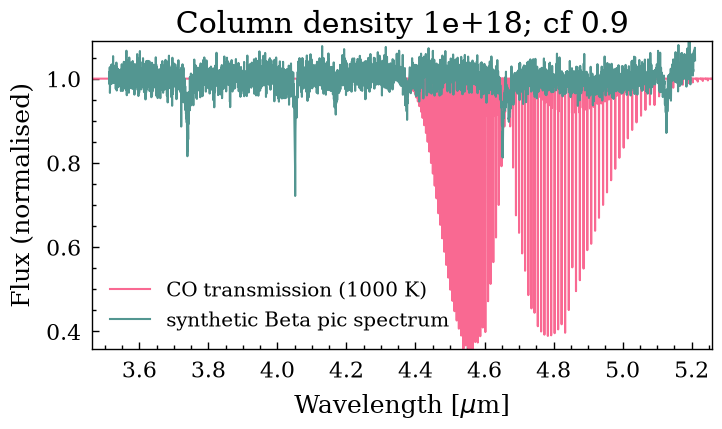

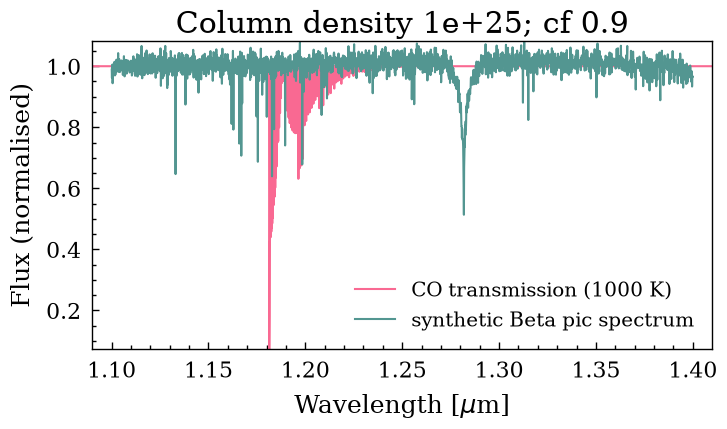

In [56]:
def plot_everything_together(synthwvl, synthflux, modelwvl, modelflux, band):

    fig, ax = plt.subplots(figsize=(8,4))
    plt.plot(modelwvl, modelflux, label=r'CO transmission (1000 K)')

    ax.ticklabel_format(useOffset=False)

    plt.plot(synthwvl, synthflux, label='synthetic Beta pic spectrum')

    plt.ylabel('Flux (normalised)')
    plt.xlabel(r'Wavelength [$\mu$m]')
    plt.legend()
    if band == 'M':
        plt.title(f'Column density {column_density}; cf {cover_fraction}')
    elif band == 'J':
        plt.title(f'Column density {cd_J}; cf {cover_fraction}')
    plt.show()
    return None

plot_everything_together(synth_wavelength_M_band, synth_flux_Mband, model_wavelength_M_band, transmission_Mband, 'M')
plot_everything_together(synth_wavelength_J_band, synth_flux_Jband, model_wavelength_J_band, transmission_Jband, 'J')

In [14]:
# fig, ax = plt.subplots()
# plt.plot(model_grid_wavelength, transmission, label=r'CO transmission (1000 K)')

# ax.ticklabel_format(useOffset=False)

# plt.plot(wavelength_with_nans_2, synth_flux_norm_2, label='synthetic Beta pic spectrum')


# plt.ylabel('Flux (normalised)')
# plt.xlabel(r'Wavelength [$\mu$m]')
# plt.legend()
# plt.title(f'Column density {column_density}; cf {cover_fraction}')
# plt.show()

# convert to DataFrame for cross_correlation function

In [57]:
def make_dfs(starwvl, starflux, tempwvl, tempflux):

    star_idx = np.argsort(starwvl)
    star_wavelength = np.asarray(starwvl)[star_idx]
    star_flux = np.asarray(starflux)[star_idx]

    template_idx = np.argsort(tempwvl)
    template_wavelength = np.asarray(tempwvl)[template_idx]
    template_flux = np.asarray(tempflux)[template_idx]

    star = pd.DataFrame({'wavelength': (star_wavelength*1000), 'flux': (star_flux)}) #CONVERT TO NM!!
    template = pd.DataFrame({'wavelength': (template_wavelength*1000), 'flux': (template_flux)}) #CONVERT TO NM!!


    print(np.min(template['wavelength']), np.max(template['wavelength']))
    print(np.min(star['wavelength']), np.max(star['wavelength']))

    lo = template["wavelength"].min() + 0.005
    hi = template["wavelength"].max() - 0.005

    star_ccf = star.loc[star["wavelength"].between(lo, hi)]

    return star_ccf, template


star_df_Mband, template_df_Mband = make_dfs(synth_wavelength_M_band, synth_flux_Mband, model_wavelength_M_band, absorption_Mband)
star_df_Jband, template_df_Jband = make_dfs(synth_wavelength_J_band, synth_flux_Jband, model_wavelength_J_band, absorption_Jband)

3463.4895234642077 5259.684040838865
3513.37256191993 5209.954306039505
1090.0158823703089 1409.9986993542514
1100.0901627148824 1399.8833048004824


# Next: cross-correlate synthetic spectrum with CO transmission

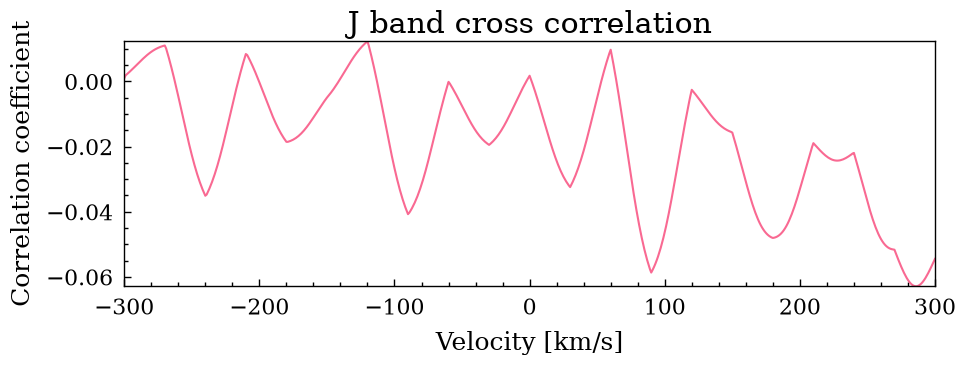

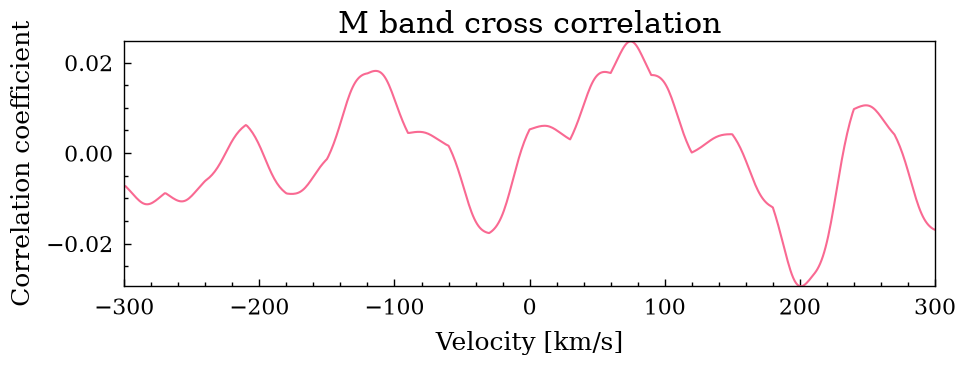

(None, None)

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cross_correlation_mod import cross_correlate

def compute_ccf(band):
# Trial velocities in km/s
    velocities = np.linspace(-300, 300, 601)

    # Compute the CCF
    if band == 'J':
        ccf = cross_correlate(
            star_df_Jband,
            template_df_Jband,
            velocities )
    
    elif band == 'M':
        ccf = cross_correlate(
            star_df_Mband,
            template_df_Mband,
            velocities)

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(velocities, ccf)
    #plt.axvline(70, color="red", linestyle="--", label="Expected velocity")
    plt.xlabel("Velocity [km/s]")
    plt.ylabel("Correlation coefficient")
    plt.title(f'{band} band cross correlation')
    #plt.legend()
    plt.tight_layout()
    plt.show()
    return None

compute_ccf('J'), compute_ccf('M')